# Import models 

In [1]:
import os
import subprocess
import pandas as pd
import numpy as np
import optuna
from optuna.samplers import NSGAIIISampler
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import AutoMinorLocator
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
import re

C:\Users\hp\anaconda3\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Simulator running script

In [2]:
# =========================
# PATHS
# =========================
ECLRUN_EXE = r"C:\ecl\macros\eclrun.exe"
BASE_DIR = r"C:\Users\hp\Desktop\Eclipsetimesteps six months"

DATA_FILE_NAME = "Egg_Model_ECL.DATA"
RSM_FILE_NAME = "Egg_Model_ECL.RSM"
RSM_PATH = os.path.join(BASE_DIR, "EGG_MODEL_ECL.RSM")

N_BLOCKS = 20
BLOCK_END_DAYS = 180  # end of each block (24*30)
TARGET_TIMES = [BLOCK_END_DAYS * i for i in range(1, N_BLOCKS + 1)]
FINAL_TIME = TARGET_TIMES[-1]

In [3]:
# =========================
# RUN ECLIPSE
# =========================
def run_eclipse():
    print("▶ Running Eclipse ...")
    cmd = [ECLRUN_EXE, "eclipse", DATA_FILE_NAME]
    subprocess.run(cmd, cwd=BASE_DIR, check=True)
    print("✔ Eclipse finished")

# =========================
# EXTRACT FOPT & FWPT PER BLOCK
# =========================
def extract_FOPT_FWPT_from_RSM(rsm_path):

    with open(rsm_path, "r") as f:
        lines = f.readlines()

    inside_summary = False
    fopt_idx = fwpt_idx = None

    for line in lines:

        if "SUMMARY OF RUN" in line:
            inside_summary = True
            fopt_idx = fwpt_idx = None
            continue

        if not inside_summary:
            continue

        tokens = line.split()
        if not tokens:
            continue

        # Detect column headers
        if fopt_idx is None and "FOPT" in tokens and "FWPT" in tokens:
            fopt_idx = tokens.index("FOPT")
            fwpt_idx = tokens.index("FWPT")
            continue

        if fopt_idx is None:
            continue

        # ✅ Only data rows have numeric TIME
        if not tokens[0][0].isdigit():
            continue
        if float(tokens[0]) == 3600.0:
            return float(tokens[fopt_idx]), float(tokens[fwpt_idx])

In [4]:
def modify_data_per_control_block(blocks_params):

    data_path = os.path.join(BASE_DIR, DATA_FILE_NAME)

    with open(data_path, "r") as f:
        lines = f.readlines()

    block_pattern = re.compile(r"--\s*Block\s+(\d+)", re.IGNORECASE)

    current_block = None
    new_lines = []

    for line in lines:

        # Detect block number
        m = block_pattern.search(line)
        if m:
            current_block = int(m.group(1))
            new_lines.append(line)
            continue

        # Skip if block not in params
        if current_block is None or current_block > len(blocks_params):
            new_lines.append(line)
            continue

        params = blocks_params[current_block - 1]
        stripped = line.strip()

        # -------------------------
        # PRODUCER BHP
        # -------------------------
        prod_match = re.match(r"'PROD(\d+)'", stripped)
        if prod_match and "'BHP'" in stripped:

            prod_num = prod_match.group(1)
            key = f"BHP{prod_num}"

            if key in params:
                bhp_value = int(params[key])

                # Replace last numeric value in line (robust)
                line = re.sub(r"(5\*\s*)(\d+)", rf"\g<1>{bhp_value}", line)

        # -------------------------
        # INJECTOR RATE
        # -------------------------
        inj_match = re.match(r"'INJECT(\d+)'", stripped)
        if inj_match and "'RATE'" in stripped:

            inj_num = inj_match.group(1)
            key = f"inj_rate{inj_num}"

            if key in params:
                rate_value = int(params[key])

                # Replace RATE value robustly
                line = re.sub(r"('RATE'\s+)(\d+)", rf"\g<1>{rate_value}", line)

        new_lines.append(line)

    with open(data_path, "w") as f:
        f.writelines(new_lines)

# Define objective optimization function

In [5]:
def objective(trial):

    # 1) Suggest parameters per control block
    blocks_params = []
    for b in range(1, N_BLOCKS + 1):
        blocks_params.append({
            "BHP1": trial.suggest_int(f"BHP1_b{b}", 150, 390),
            "BHP2": trial.suggest_int(f"BHP2_b{b}", 150, 390),
            "BHP3": trial.suggest_int(f"BHP3_b{b}", 150, 390),
            "BHP4": trial.suggest_int(f"BHP4_b{b}", 150, 390),
            "inj_rate1": trial.suggest_int(f"inj_rate1_b{b}", 50, 400),
            "inj_rate2": trial.suggest_int(f"inj_rate2_b{b}", 50, 400),
            "inj_rate3": trial.suggest_int(f"inj_rate3_b{b}", 50, 400),
            "inj_rate4": trial.suggest_int(f"inj_rate4_b{b}", 50, 400),
            "inj_rate5": trial.suggest_int(f"inj_rate5_b{b}", 50, 400),
            "inj_rate6": trial.suggest_int(f"inj_rate6_b{b}", 50, 400),
            "inj_rate7": trial.suggest_int(f"inj_rate7_b{b}", 50, 400),
            "inj_rate8": trial.suggest_int(f"inj_rate8_b{b}", 50, 400),
        })

    # 2) Update schedule per CONTROL BLOCK (BHP + RATE)
    modify_data_per_control_block(blocks_params)

    run_eclipse()
    # 3) Extract FOPT/FWPT at block end times
    fopt, fwpt = extract_FOPT_FWPT_from_RSM(RSM_PATH)
    return fopt, fwpt

# Optimization running 

In [6]:
sampler = optuna.samplers.TPESampler(
    n_startup_trials=42,
    multivariate=False,
    seed=42)

study = optuna.create_study(
    directions=["maximize", "minimize"],
    sampler=sampler,
    study_name="ECLIPSE_SUM_DELTA_FOPT_FWPT"
)

study.optimize(objective, n_trials=100, show_progress_bar=False)

[I 2026-11-07 22:55:26,472] A new study created in memory with name: ECLIPSE_SUM_DELTA_FOPT_FWPT


▶ Running Eclipse ...


[I 2026-11-07 22:58:56,502] Trial 0 finished with values: [537265.4, 4725243.0] and parameters: {'BHP1_b1': 240, 'BHP2_b1': 379, 'BHP3_b1': 326, 'BHP4_b1': 294, 'inj_rate1_b1': 104, 'inj_rate2_b1': 104, 'inj_rate3_b1': 70, 'inj_rate4_b1': 354, 'inj_rate5_b1': 260, 'inj_rate6_b1': 298, 'inj_rate7_b1': 57, 'inj_rate8_b1': 390, 'BHP1_b2': 350, 'BHP2_b2': 201, 'BHP3_b2': 193, 'BHP4_b2': 194, 'inj_rate1_b2': 156, 'inj_rate2_b2': 234, 'inj_rate3_b2': 201, 'inj_rate4_b2': 152, 'inj_rate5_b2': 264, 'inj_rate6_b2': 98, 'inj_rate7_b2': 152, 'inj_rate8_b2': 178, 'BHP1_b3': 259, 'BHP2_b3': 339, 'BHP3_b3': 198, 'BHP4_b3': 273, 'inj_rate1_b3': 257, 'inj_rate2_b3': 66, 'inj_rate3_b3': 263, 'inj_rate4_b3': 109, 'inj_rate5_b3': 72, 'inj_rate6_b3': 383, 'inj_rate7_b3': 388, 'inj_rate8_b3': 333, 'BHP1_b4': 223, 'BHP2_b4': 173, 'BHP3_b4': 314, 'BHP4_b4': 256, 'inj_rate1_b4': 92, 'inj_rate2_b4': 223, 'inj_rate3_b4': 62, 'inj_rate4_b4': 369, 'inj_rate5_b4': 140, 'inj_rate6_b4': 282, 'inj_rate7_b4': 159, 'in

✔ Eclipse finished
▶ Running Eclipse ...


[I 2026-11-07 23:01:25,365] Trial 1 finished with values: [541618.4, 4917360.0] and parameters: {'BHP1_b1': 376, 'BHP2_b1': 379, 'BHP3_b1': 370, 'BHP4_b1': 239, 'inj_rate1_b1': 55, 'inj_rate2_b1': 375, 'inj_rate3_b1': 200, 'inj_rate4_b1': 389, 'inj_rate5_b1': 388, 'inj_rate6_b1': 349, 'inj_rate7_b1': 153, 'inj_rate8_b1': 185, 'BHP1_b2': 355, 'BHP2_b2': 226, 'BHP3_b2': 190, 'BHP4_b2': 284, 'inj_rate1_b2': 378, 'inj_rate2_b2': 294, 'inj_rate3_b2': 250, 'inj_rate4_b2': 84, 'inj_rate5_b2': 265, 'inj_rate6_b2': 397, 'inj_rate7_b2': 99, 'inj_rate8_b2': 231, 'BHP1_b3': 361, 'BHP2_b3': 328, 'BHP3_b3': 317, 'BHP4_b3': 319, 'inj_rate1_b3': 176, 'inj_rate2_b3': 153, 'inj_rate3_b3': 334, 'inj_rate4_b3': 334, 'inj_rate5_b3': 354, 'inj_rate6_b3': 370, 'inj_rate7_b3': 229, 'inj_rate8_b3': 226, 'BHP1_b4': 342, 'BHP2_b4': 306, 'BHP3_b4': 319, 'BHP4_b4': 341, 'inj_rate1_b4': 362, 'inj_rate2_b4': 168, 'inj_rate3_b4': 181, 'inj_rate4_b4': 82, 'inj_rate5_b4': 252, 'inj_rate6_b4': 62, 'inj_rate7_b4': 213, '

✔ Eclipse finished
▶ Running Eclipse ...


... (192 outputs left out)

[I 2026-11-08 09:58:29,115] Trial 98 finished with values: [543909.5, 5089010.0] and parameters: {'BHP1_b1': 154, 'BHP2_b1': 341, 'BHP3_b1': 163, 'BHP4_b1': 380, 'inj_rate1_b1': 61, 'inj_rate2_b1': 359, 'inj_rate3_b1': 85, 'inj_rate4_b1': 99, 'inj_rate5_b1': 148, 'inj_rate6_b1': 75, 'inj_rate7_b1': 264, 'inj_rate8_b1': 219, 'BHP1_b2': 262, 'BHP2_b2': 266, 'BHP3_b2': 218, 'BHP4_b2': 390, 'inj_rate1_b2': 272, 'inj_rate2_b2': 107, 'inj_rate3_b2': 297, 'inj_rate4_b2': 91, 'inj_rate5_b2': 88, 'inj_rate6_b2': 147, 'inj_rate7_b2': 156, 'inj_rate8_b2': 278, 'BHP1_b3': 159, 'BHP2_b3': 216, 'BHP3_b3': 177, 'BHP4_b3': 354, 'inj_rate1_b3': 79, 'inj_rate2_b3': 216, 'inj_rate3_b3': 207, 'inj_rate4_b3': 134, 'inj_rate5_b3': 169, 'inj_rate6_b3': 289, 'inj_rate7_b3': 138, 'inj_rate8_b3': 287, 'BHP1_b4': 296, 'BHP2_b4': 155, 'BHP3_b4': 226, 'BHP4_b4': 265, 'inj_rate1_b4': 345, 'inj_rate2_b4': 240, 'inj_rate3_b4': 198, 'inj_rate4_b4': 121, 'inj_rate5_b4': 91, 'inj_rate6_b4': 200, 'inj_rate7_b4': 51, 'inj

✔ Eclipse finished
▶ Running Eclipse ...


[I 2026-11-08 10:01:55,863] Trial 99 finished with values: [551149.2, 5995685.0] and parameters: {'BHP1_b1': 176, 'BHP2_b1': 280, 'BHP3_b1': 246, 'BHP4_b1': 375, 'inj_rate1_b1': 68, 'inj_rate2_b1': 184, 'inj_rate3_b1': 150, 'inj_rate4_b1': 65, 'inj_rate5_b1': 331, 'inj_rate6_b1': 65, 'inj_rate7_b1': 242, 'inj_rate8_b1': 268, 'BHP1_b2': 251, 'BHP2_b2': 181, 'BHP3_b2': 202, 'BHP4_b2': 278, 'inj_rate1_b2': 261, 'inj_rate2_b2': 59, 'inj_rate3_b2': 306, 'inj_rate4_b2': 108, 'inj_rate5_b2': 51, 'inj_rate6_b2': 288, 'inj_rate7_b2': 269, 'inj_rate8_b2': 253, 'BHP1_b3': 356, 'BHP2_b3': 188, 'BHP3_b3': 297, 'BHP4_b3': 378, 'inj_rate1_b3': 188, 'inj_rate2_b3': 84, 'inj_rate3_b3': 183, 'inj_rate4_b3': 120, 'inj_rate5_b3': 193, 'inj_rate6_b3': 268, 'inj_rate7_b3': 304, 'inj_rate8_b3': 190, 'BHP1_b4': 263, 'BHP2_b4': 160, 'BHP3_b4': 213, 'BHP4_b4': 279, 'inj_rate1_b4': 271, 'inj_rate2_b4': 337, 'inj_rate3_b4': 279, 'inj_rate4_b4': 324, 'inj_rate5_b4': 65, 'inj_rate6_b4': 187, 'inj_rate7_b4': 152, 'i

✔ Eclipse finished


In [7]:
pareto = study.best_trials  # Pareto front

for i, t in enumerate(pareto[:10], start=1):
    print(f"\n--- Pareto solution {i} ---")
    print("ΣΔFOPT:", t.values[0], " ΣΔFWPT:", t.values[1])
    # print some parameters
    for k in sorted(t.params.keys()):
        print(k, "=", t.params[k])


--- Pareto solution 1 ---
ΣΔFOPT: 543890.4  ΣΔFWPT: 4903860.0
BHP1_b1 = 306
BHP1_b10 = 207
BHP1_b11 = 211
BHP1_b12 = 199
BHP1_b13 = 374
BHP1_b14 = 216
BHP1_b15 = 303
BHP1_b16 = 331
BHP1_b17 = 297
BHP1_b18 = 289
BHP1_b19 = 223
BHP1_b2 = 192
BHP1_b20 = 320
BHP1_b3 = 307
BHP1_b4 = 260
BHP1_b5 = 220
BHP1_b6 = 319
BHP1_b7 = 367
BHP1_b8 = 356
BHP1_b9 = 274
BHP2_b1 = 299
BHP2_b10 = 273
BHP2_b11 = 237
BHP2_b12 = 274
BHP2_b13 = 245
BHP2_b14 = 245
BHP2_b15 = 162
BHP2_b16 = 167
BHP2_b17 = 360
BHP2_b18 = 160
BHP2_b19 = 340
BHP2_b2 = 356
BHP2_b20 = 315
BHP2_b3 = 376
BHP2_b4 = 358
BHP2_b5 = 369
BHP2_b6 = 280
BHP2_b7 = 355
BHP2_b8 = 275
BHP2_b9 = 253
BHP3_b1 = 234
BHP3_b10 = 175
BHP3_b11 = 263
BHP3_b12 = 151
BHP3_b13 = 170
BHP3_b14 = 251
BHP3_b15 = 212
BHP3_b16 = 169
BHP3_b17 = 324
BHP3_b18 = 179
BHP3_b19 = 257
BHP3_b2 = 204
BHP3_b20 = 240
BHP3_b3 = 359
BHP3_b4 = 281
BHP3_b5 = 331
BHP3_b6 = 173
BHP3_b7 = 310
BHP3_b8 = 165
BHP3_b9 = 226
BHP4_b1 = 352
BHP4_b10 = 242
BHP4_b11 = 161
BHP4_b12 = 151
BHP4_

# The plot of FOPT & FWPT  for the base case:

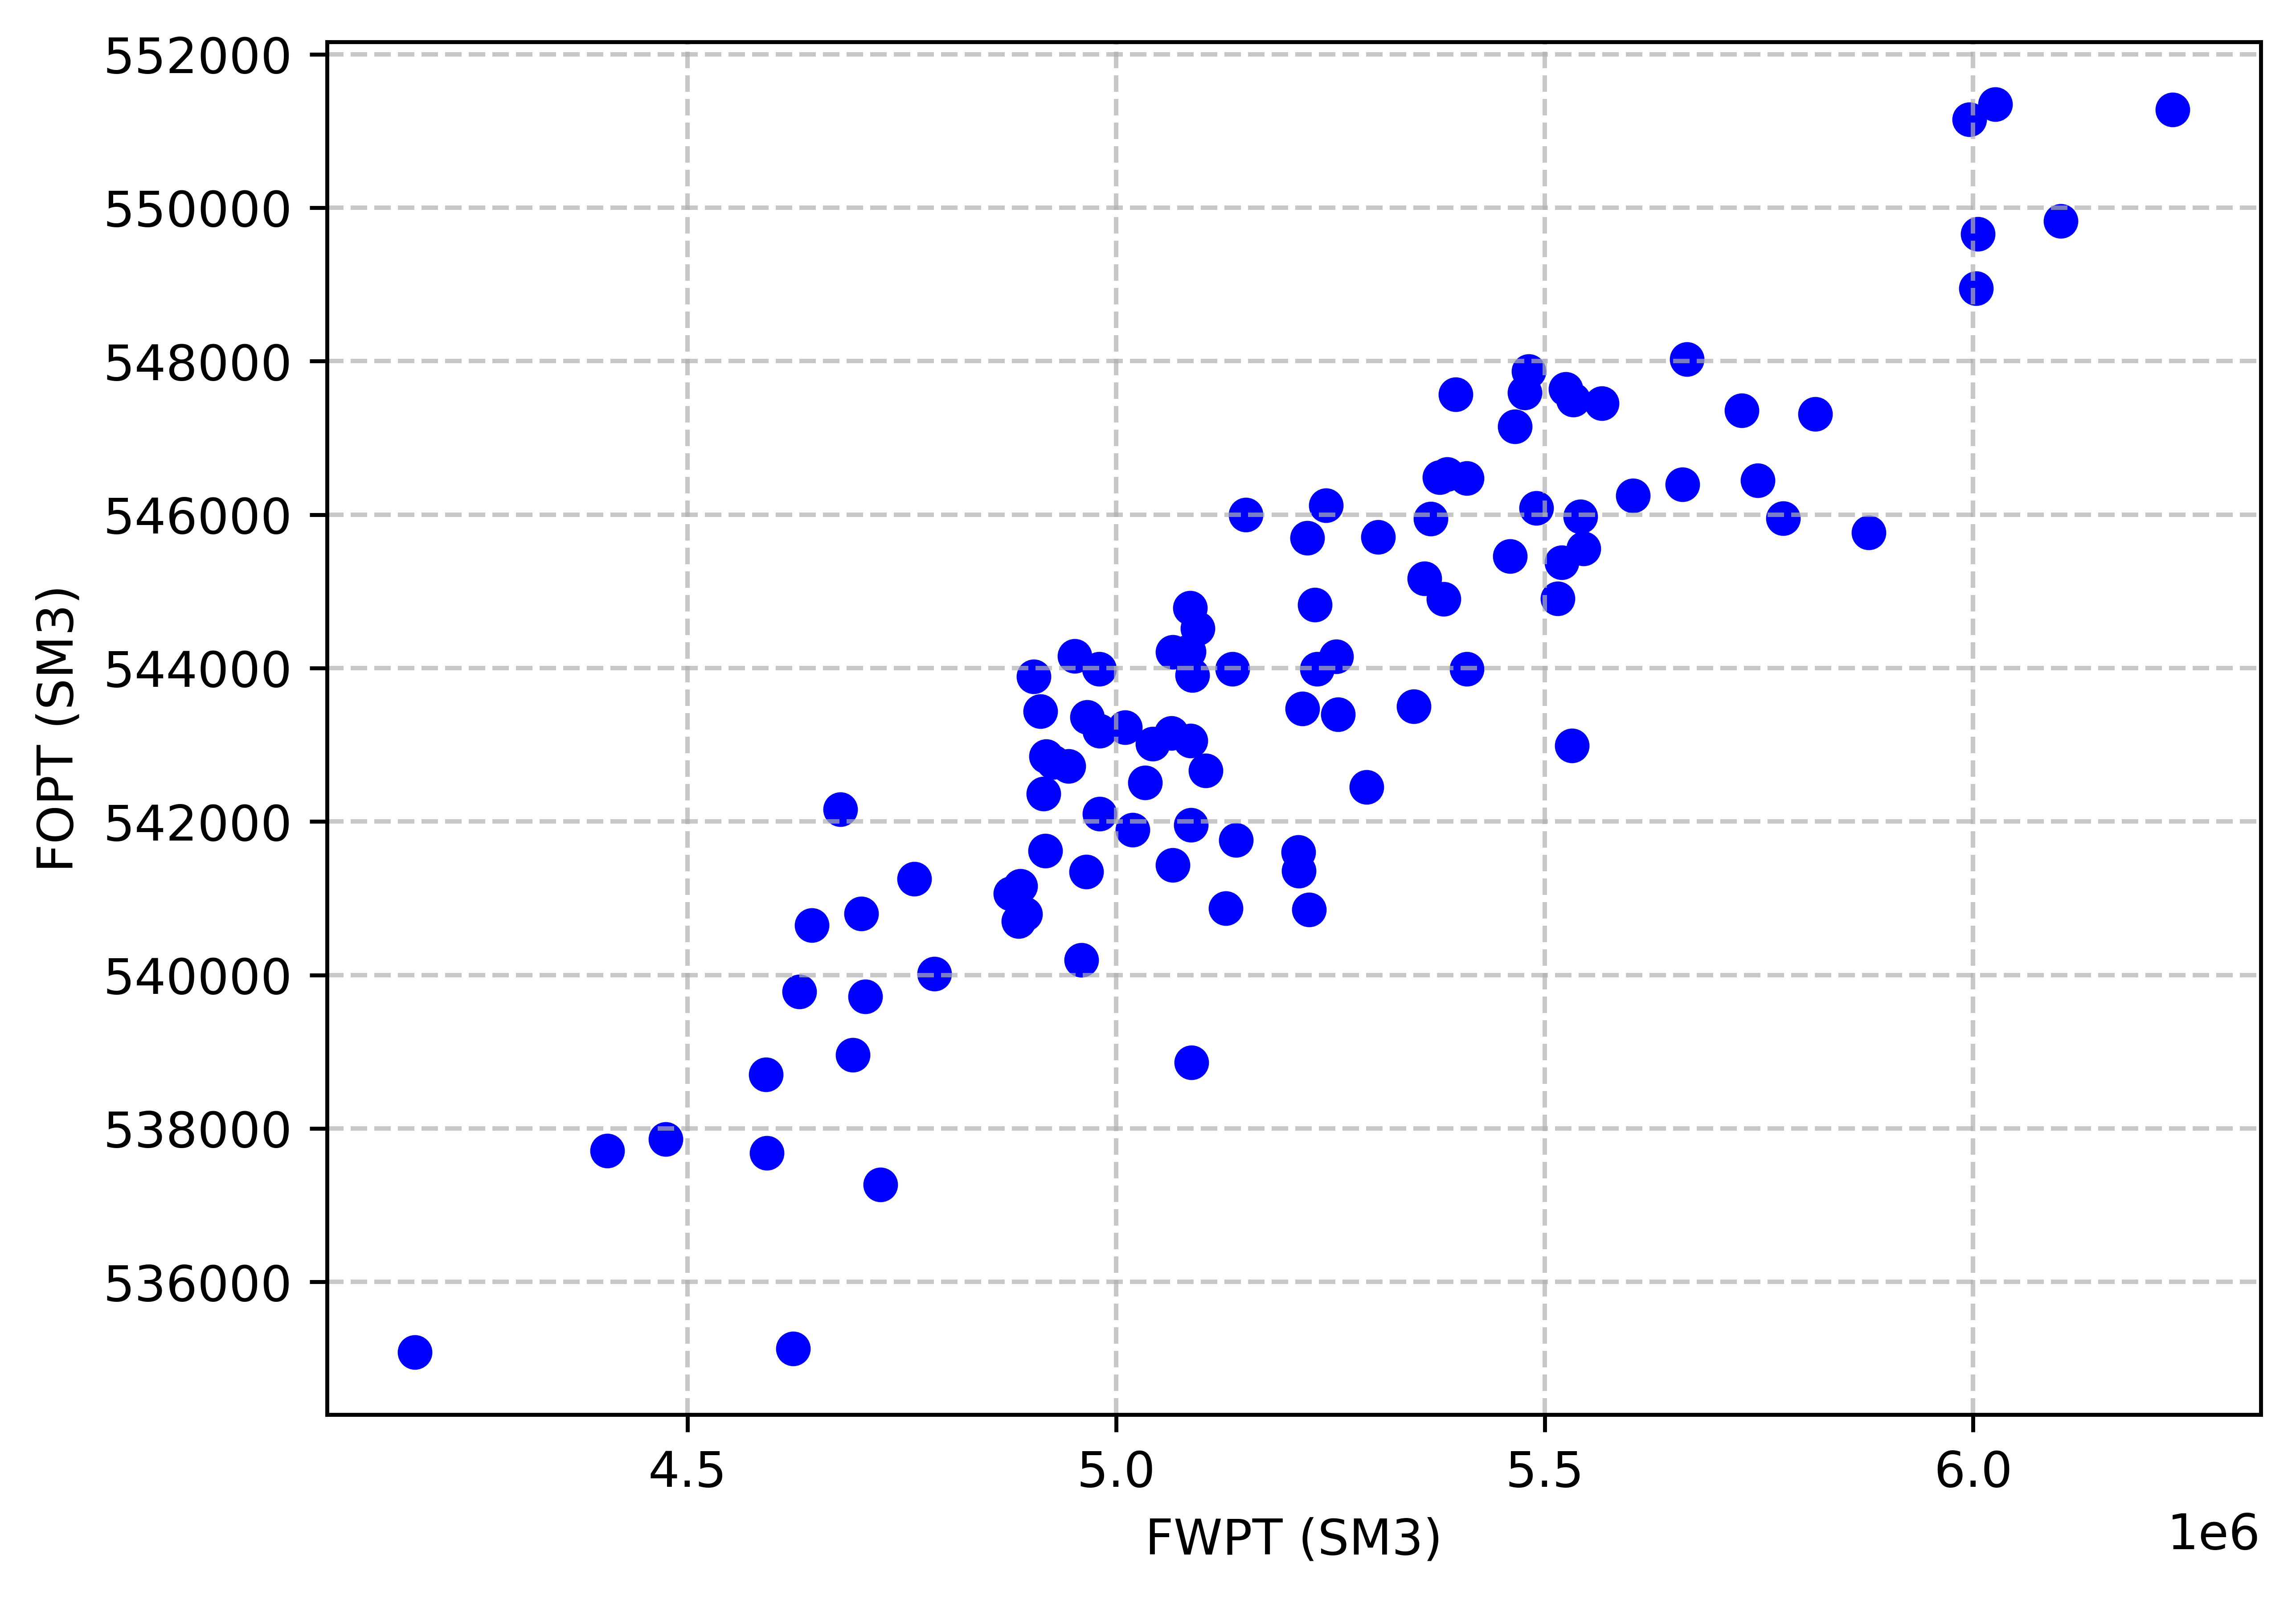

In [18]:
pareto_trials1 = study.best_trials
fopts1 = [t.values[0] for t in study.trials if t.values is not None]
fwpts1 = [t.values[1] for t in study.trials if t.values is not None]

plt.figure(figsize=(7,5),dpi=800)
plt.scatter(fwpts1, fopts1, c='blue')
plt.xlabel("FWPT (SM3)")
plt.ylabel("FOPT (SM3)")
plt.grid(True, which="major", linestyle="--", linewidth=0.9, alpha=0.7)
plt.grid(True, which="minor", linestyle="--", linewidth=0.5, alpha=0.4)
plt.show()

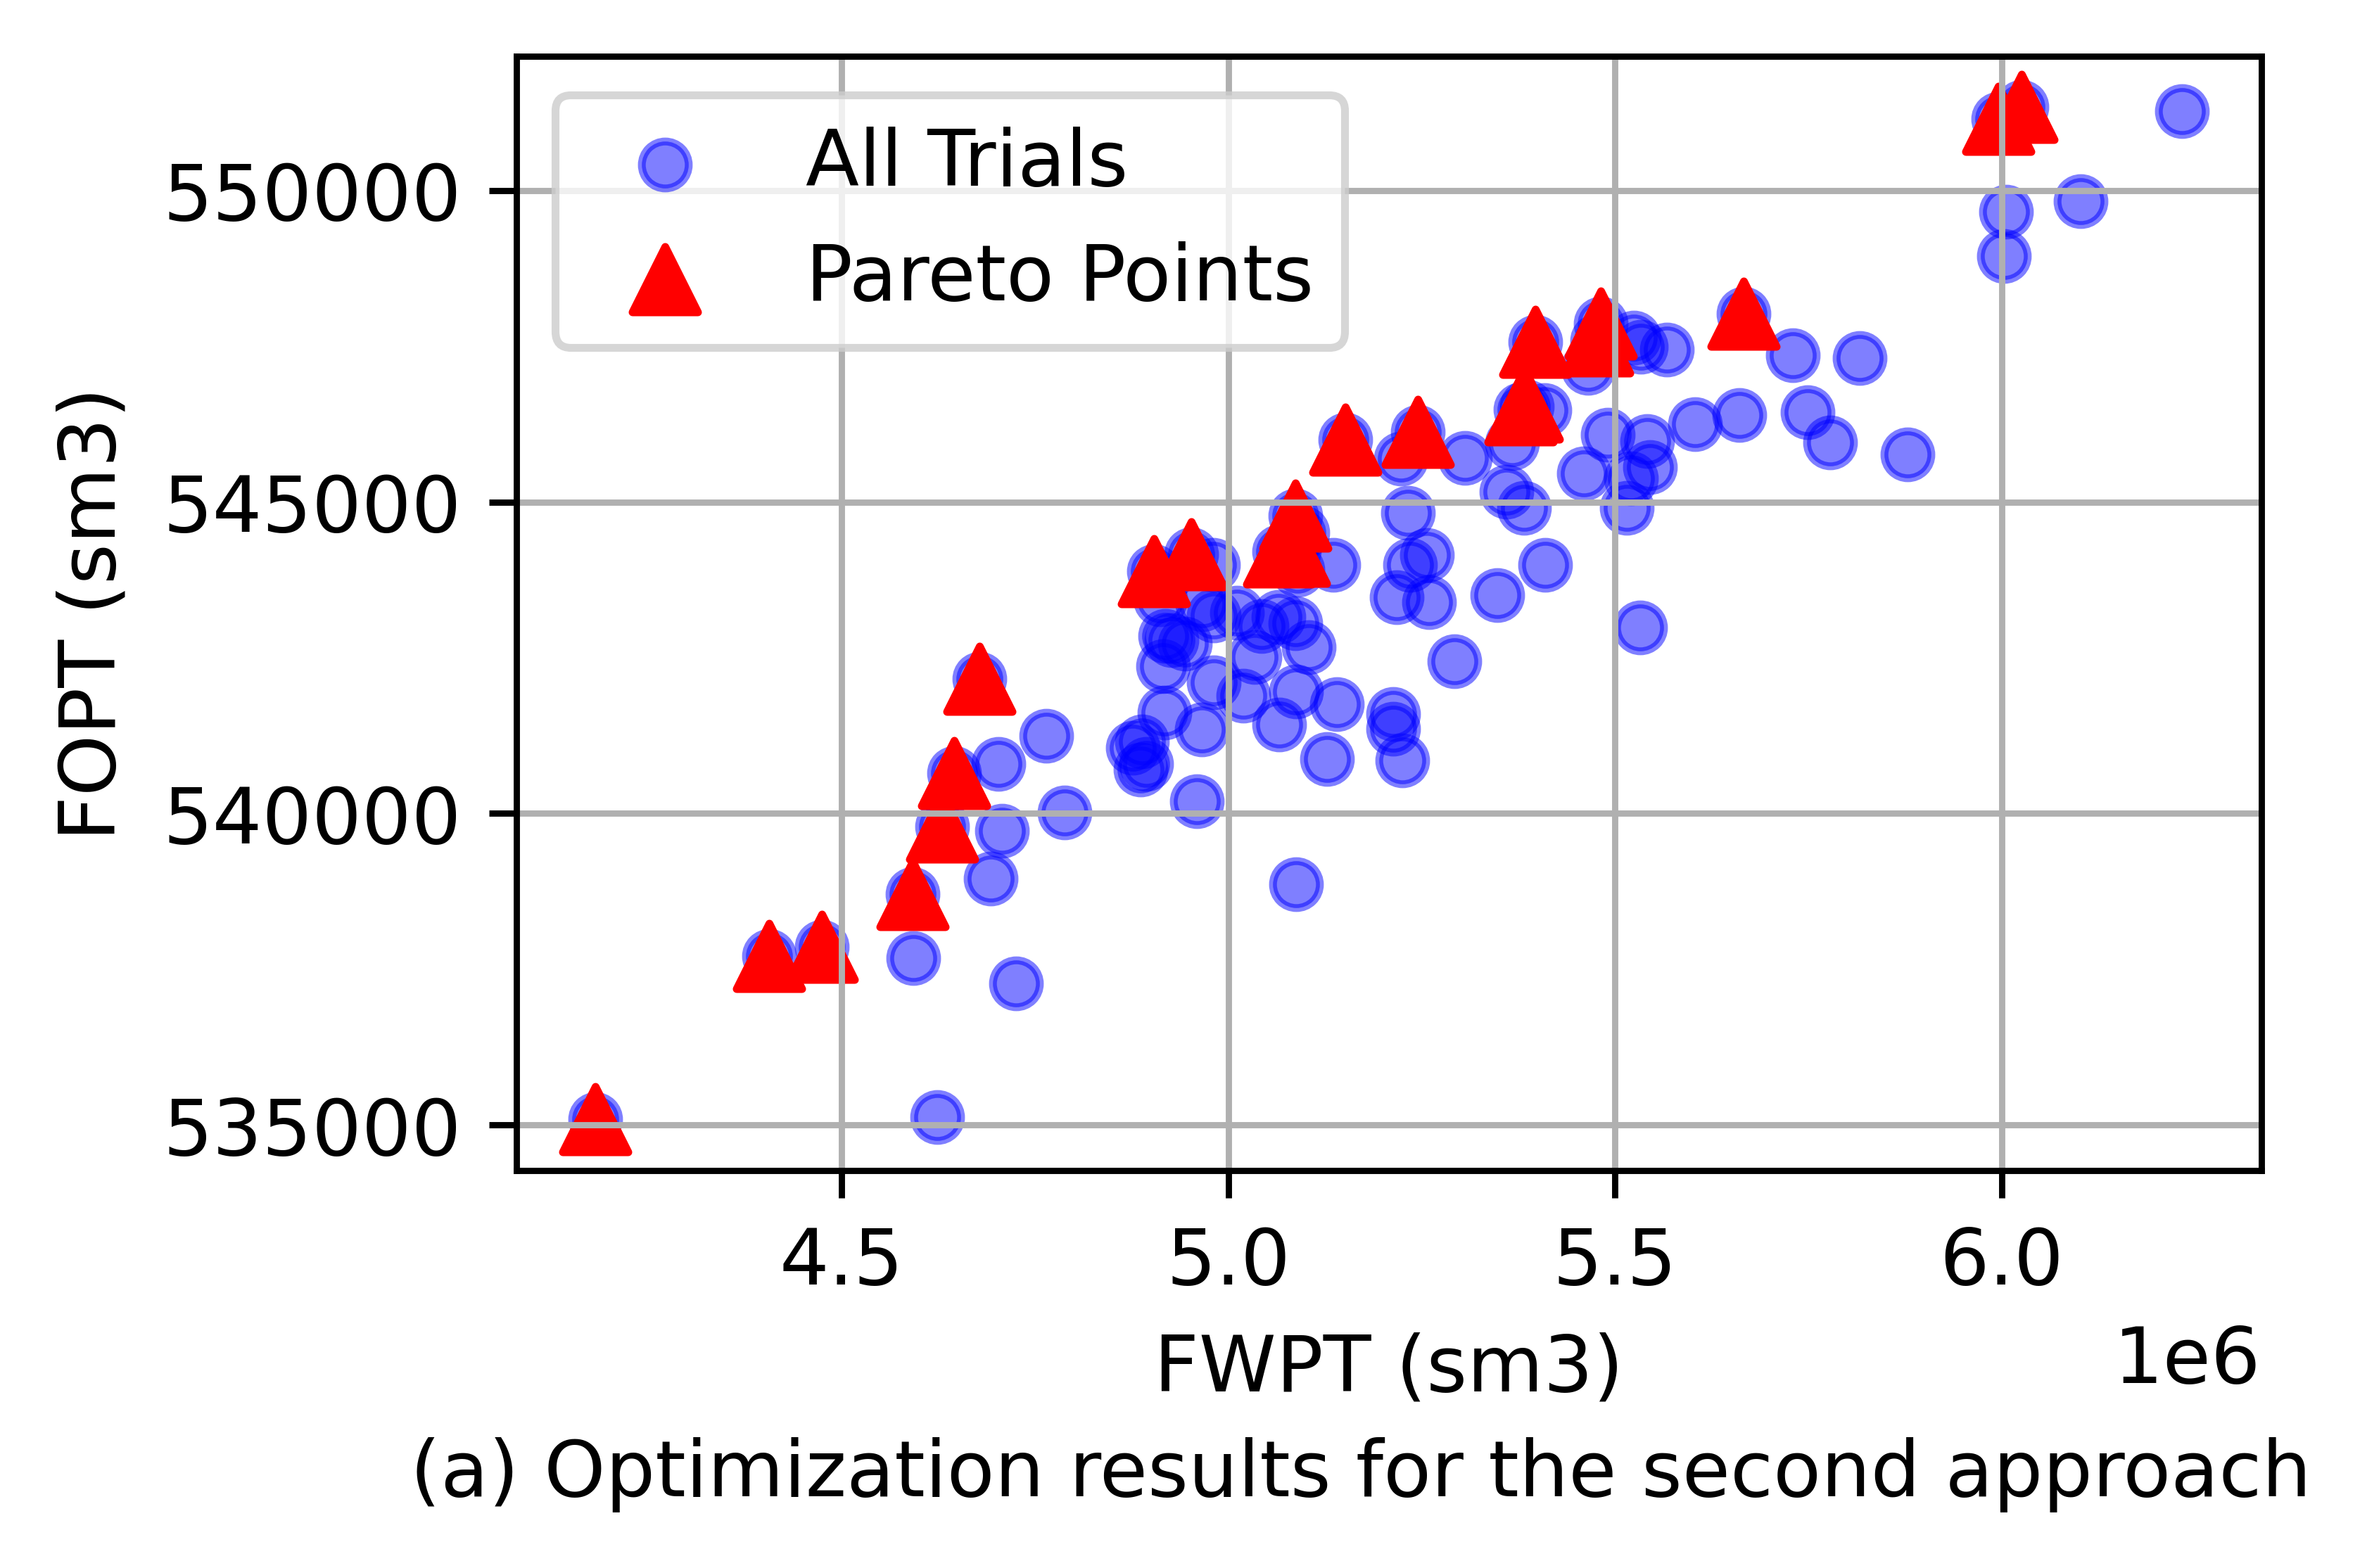

In [19]:
# --- Pareto optimal trials ---
pareto_trials1 = study.best_trials
pareto_fopts = [t.values[0] for t in pareto_trials1]
pareto_fwpts = [t.values[1] for t in pareto_trials1]

# --- Sort Pareto points by FWPT (minimization axis) ---
pareto_points = sorted(zip(pareto_fwpts, pareto_fopts))
pareto_fwpts_sorted, pareto_fopts_sorted = zip(*pareto_points)

# --- All trials ---
fopts = [t.values[0] for t in study.trials if t.values is not None]
fwpts = [t.values[1] for t in study.trials if t.values is not None]

# Create figure
fig, ax = plt.subplots(figsize=(4, 3), dpi=800)

# All solutions
ax.scatter(
    fwpts,
    fopts,
    color='blue',
    alpha=0.5,
    label='All Trials'
)

# Pareto points
ax.scatter(
    pareto_fwpts_sorted,
    pareto_fopts_sorted,
    color='red',
    marker='^',
    s=70,
    label='Pareto Points'
)

# Labels
ax.set_xlabel("FWPT (sm3)")
ax.set_ylabel("FOPT (sm3)")

# Legend and grid
ax.legend()
ax.grid(True)

# Leave space for caption
plt.subplots_adjust(bottom=0.22)

# Add caption below the figure
fig.text(
    0.5,
    0.04,
    "(a) Optimization results for the second approach",
    ha="center",
    va="center",
    fontsize=10
)

# Save (optional)
plt.savefig(
    "Optimization_results_second_approach.png",
    dpi=800,
    bbox_inches="tight"
)

plt.show()

# Pareto front optimal results

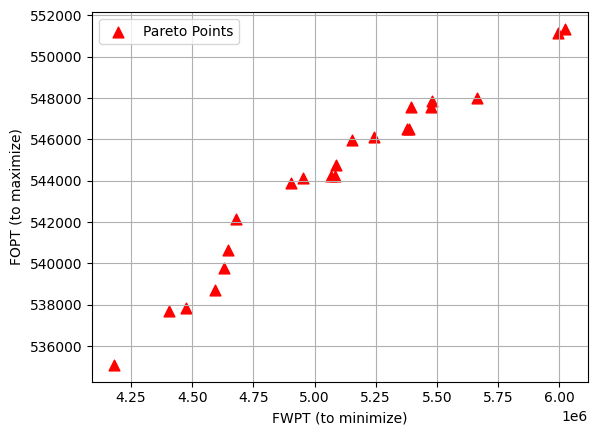

In [20]:
plt.figure()
# Pareto points
plt.scatter(pareto_fwpts_sorted, pareto_fopts_sorted,
            color='red', s=60, label='Pareto Points', marker='^')
plt.xlabel("FWPT (to minimize)")
plt.ylabel("FOPT (to maximize)")
plt.legend()
plt.grid(True)

plt.show()

In [21]:
print("\nPareto Front Table\n")
print("Trial\tFOPT\tFWPT")

for trial in pareto_trials1:
    print(f"{trial.number}\t{trial.values[0]:.2f}\t{trial.values[1]:.2f}")


Pareto Front Table

Trial	FOPT	FWPT
9	543890.40	4903860.00
14	547867.70	5481618.00
17	544208.10	5066220.00
22	546122.10	5245168.00
32	544216.30	5084744.00
35	551348.90	6025592.00
43	548026.50	5666322.00
49	546484.80	5377613.00
50	542159.20	4678196.00
52	544156.90	4952080.00
54	547566.80	5396466.00
55	545995.90	5151318.00
60	547590.10	5476938.00
61	537862.90	4474384.00
64	537707.80	4406332.00
81	535085.40	4181953.00
84	546528.30	5386362.00
85	540646.10	4645276.00
86	539784.60	4630456.00
89	544783.40	5086444.00
93	538701.40	4591829.00
99	551149.20	5995685.00


In [22]:
# ===============================
# Constraint definition
# ===============================
FWPT_max = 6200000  # constraint on water production

# Extract Pareto values
fopt = np.array([t.values[0] for t in pareto_trials1])
fwpt = np.array([t.values[1] for t in pareto_trials1])

# ===============================
# Apply constraint (FWPT <= limit)
# ===============================
valid_indices = [i for i, fw in enumerate(fwpt) if fw <= FWPT_max]

if valid_indices:

    # Select best FOPT among valid ones
    best_idx = max(valid_indices, key=lambda i: fopt[i])
    best_trial_constraint = pareto_trials1[best_idx]

    # --- Extract values ---
    best_fopt = best_trial_constraint.values[0]
    best_fwpt = best_trial_constraint.values[1]
    params = best_trial_constraint.params

    # --- Separate BHP and Injection rates ---
    bhp_params = {k: v for k, v in params.items() if "BHP" in k}
    inj_params = {k: v for k, v in params.items() if "inj" in k.lower()}

    # --- Print results ---
    print("========== CONSTRAINED OPTIMAL SOLUTION ==========")
    print(f"Trial Number : {best_trial_constraint.number}")
    print(f"FOPT         : {best_fopt}")
    print(f"FWPT         : {best_fwpt}")

    print("\n--- BHP Parameters ---")
    for k, v in bhp_params.items():
        print(f"{k}: {v}")

    print("\n--- Injection Rate Parameters ---")
    for k, v in inj_params.items():
        print(f"{k}: {v}")

else:
    print("No Pareto solution satisfies the FWPT constraint.")

========== CONSTRAINED OPTIMAL SOLUTION ==========
Trial Number : 35
FOPT         : 551348.9
FWPT         : 6025592.0

--- BHP Parameters ---
BHP1_b1: 270
BHP2_b1: 374
BHP3_b1: 290
BHP4_b1: 279
BHP1_b2: 234
BHP2_b2: 258
BHP3_b2: 182
BHP4_b2: 161
BHP1_b3: 181
BHP2_b3: 224
BHP3_b3: 178
BHP4_b3: 387
BHP1_b4: 258
BHP2_b4: 155
BHP3_b4: 304
BHP4_b4: 249
BHP1_b5: 178
BHP2_b5: 339
BHP3_b5: 312
BHP4_b5: 177
BHP1_b6: 381
BHP2_b6: 367
BHP3_b6: 215
BHP4_b6: 343
BHP1_b7: 256
BHP2_b7: 191
BHP3_b7: 360
BHP4_b7: 319
BHP1_b8: 323
BHP2_b8: 334
BHP3_b8: 172
BHP4_b8: 273
BHP1_b9: 389
BHP2_b9: 283
BHP3_b9: 191
BHP4_b9: 226
BHP1_b10: 370
BHP2_b10: 219
BHP3_b10: 194
BHP4_b10: 307
BHP1_b11: 259
BHP2_b11: 252
BHP3_b11: 187
BHP4_b11: 252
BHP1_b12: 284
BHP2_b12: 339
BHP3_b12: 280
BHP4_b12: 228
BHP1_b13: 245
BHP2_b13: 273
BHP3_b13: 343
BHP4_b13: 240
BHP1_b14: 166
BHP2_b14: 293
BHP3_b14: 336
BHP4_b14: 349
BHP1_b15: 258
BHP2_b15: 216
BHP3_b15: 244
BHP4_b15: 243
BHP1_b16: 215
BHP2_b16: 335
BHP3_b16: 363
BHP4_b16: 20

In [23]:
pareto_numbers = {t.number for t in study.best_trials}

df = pd.DataFrame([
    {
        "Trial": t.number,
        "FOPT": t.values[0],
        "FWPT": t.values[1],
        "Pareto": t.number in pareto_numbers
    }
    for t in study.trials
    if t.values is not None
])

df.to_csv("results_6months.csv", index=False)